In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv("IMDB Dataset.csv")
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


<Axes: xlabel='sentiment', ylabel='count'>

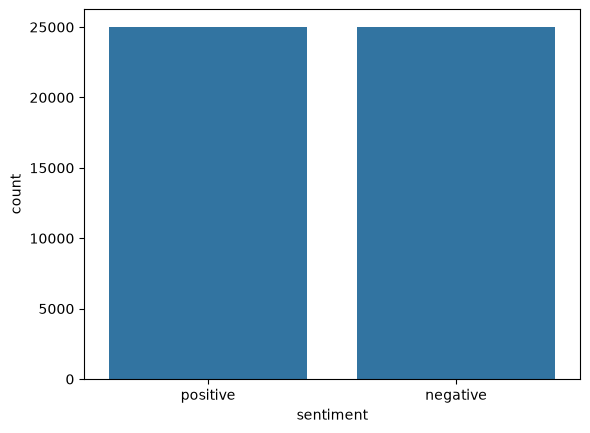

In [3]:
sns.countplot(x=df['sentiment'])


In [4]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [5]:
def posneg(args):
    if args=='positive':
        return 1
    else:
        return 0   
    


In [6]:
df['sentiment']=df['sentiment'].apply(posneg)

In [7]:
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1
...,...,...
49995,I thought this movie did a down right good job...,1
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",0
49997,I am a Catholic taught in parochial elementary...,0
49998,I'm going to have to disagree with the previou...,0


In [8]:
from nltk.stem import SnowballStemmer
import re
import string
from nltk.corpus import stopwords

In [9]:
_sbs    = SnowballStemmer('english')
_STOP  = set(stopwords.words('english'))
_URL   = re.compile(r'https?://\S+|www\.\S+')
_HTML  = re.compile(r'<.*?>', re.DOTALL)
_BRACK = re.compile(r'\[.*?\]', re.DOTALL)
_PUNCT = re.compile(f"[{re.escape(string.punctuation.replace(chr(39), ''))}]")  # keeps apostrophe
_DIGIT = re.compile(r'\w*\d\w*')

In [10]:
def wordopt(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = _URL.sub(' ', text)
    text = _HTML.sub(' ', text)
    text = _BRACK.sub(' ', text)
    text = _PUNCT.sub(' ', text)
    text = _DIGIT.sub(' ', text)
    words = [w for w in text.split() if w not in _STOP]       # "don't" matched before apostrophe is stripped
    words = [_sbs.stem(w.replace("'", "")) for w in words]
    return ' '.join(w for w in words if w)

In [11]:
df['review']=df['review'].apply(wordopt)

In [12]:
df

,review,sentiment
0,one review mention watch oz episod hook right ...,1
1,wonder littl product film techniqu unassum old...,1
2,thought wonder way spend time hot summer weeke...,1
3,basic there famili littl boy jake think there ...,0
4,petter mattei love time money visual stun film...,1
...,...,...
49995,thought movi right good job creativ origin fir...,1
49996,bad plot bad dialogu bad act idiot direct anno...,0
49997,cathol taught parochi elementari school nun ta...,0
49998,go disagre previous comment side maltin one se...,0


In [13]:
X=df['review']
Y=df['sentiment']

In [14]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

tv=TfidfVectorizer(max_features=50000,ngram_range=(1,2))
X_train=tv.fit_transform(X_train).toarray()
X_test=tv.transform(X_test).toarray()

In [16]:
X_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(40000, 50000))

In [17]:
tv.vocabulary_

{'that': np.int64(43313),
 'kept': np.int64(22137),
 'ask': np.int64(2485),
 'mani': np.int64(26184),
 'fight': np.int64(14287),
 'scream': np.int64(37681),
 'match': np.int64(26485),
 'swear': np.int64(42606),
 'general': np.int64(16692),
 'mayhem': np.int64(26691),
 'permeat': np.int64(32560),
 'minut': np.int64(27373),
 'comparison': np.int64(7836),
 'also': np.int64(1232),
 'stand': np.int64(41056),
 'think': np.int64(43691),
 'one': np.int64(30642),
 'dimension': np.int64(10127),
 'charact': np.int64(6424),
 'littl': np.int64(24386),
 'depth': np.int64(9746),
 'virtual': np.int64(46908),
 'imposs': np.int64(20704),
 'care': np.int64(5861),
 'happen': np.int64(19037),
 'bad': np.int64(3047),
 'written': np.int64(49541),
 'cypher': np.int64(9005),
 'director': np.int64(10234),
 'hang': np.int64(19019),
 'belief': np.int64(3758),
 'topic': np.int64(44902),
 'done': np.int64(10627),
 'much': np.int64(28844),
 'better': np.int64(4060),
 'drama': np.int64(10815),
 'tv': np.int64(45577),

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [19]:
from sklearn.metrics import accuracy_score

In [20]:
def Algorithms(X_train,Y_train,X_test,Y_test):
    models={
    'Lr':LogisticRegression(),
    'Rf':RandomForestClassifier(n_estimators=100,n_jobs=1,max_depth=30),
    'Xgb':XGBClassifier(n_estimators=150,n_jobs=1),
    }
    result=[]
    for name,model in models.items():
        model.fit(X_train,Y_train)
        pred=model.predict(X_test)
        acc_score=accuracy_score(Y_test,pred)
        result.append({
            'model_name':name,
            'model_score':acc_score,
        })   
    new_result_df=pd.DataFrame(result)
    return new_result_df
    

In [21]:
#Algorithms(X_train,Y_train,X_test,Y_test)

In [22]:
'''from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

param_grid = {
    'penalty': ['l1', 'l2'],
    
}

grid = GridSearchCV(
    LogisticRegression(solver='liblinear', max_iter=100, random_state=42),
    param_grid=param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1,
    verbose=1,
)

grid.fit(X_train, Y_train)

print(f"Best Parameters: {grid.best_params_}")
print(f"Best CV F1:      {grid.best_score_:.4f}")

best_model = grid.best_estimator_   
print(classification_report(Y_test, best_model.predict(X_test)))
'''

'from sklearn.linear_model import LogisticRegression\nfrom sklearn.model_selection import GridSearchCV\nfrom sklearn.metrics import classification_report\n\nparam_grid = {\n    \'penalty\': [\'l1\', \'l2\'],\n\n}\n\ngrid = GridSearchCV(\n    LogisticRegression(solver=\'liblinear\', max_iter=100, random_state=42),\n    param_grid=param_grid,\n    scoring=\'f1\',\n    cv=3,\n    n_jobs=-1,\n    verbose=1,\n)\n\ngrid.fit(X_train, Y_train)\n\nprint(f"Best Parameters: {grid.best_params_}")\nprint(f"Best CV F1:      {grid.best_score_:.4f}")\n\nbest_model = grid.best_estimator_   \nprint(classification_report(Y_test, best_model.predict(X_test)))\n'

In [23]:
lr = LogisticRegression()



In [24]:
lr.fit(X_train,Y_train)

KeyboardInterrupt: 

In [ ]:
lr.score(X_test,Y_test)

NotFittedError: This LogisticRegression instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [ ]:
lr.score(X_train,Y_train)

In [25]:
from sklearn.pipeline import Pipeline
pipe=Pipeline([('Tfidf',TfidfVectorizer(preprocessor=wordopt)),('classifier',lr)])


In [26]:
pipe.fit(X,Y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",<function wor...002D8EBEA16F0>
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


In [27]:
pipe.predict(["The movie was absolutely fantastic! The storyline was engaging, the acting was outstanding, and the cinematography was beautiful. The characters were well-developed, and the emotional scenes made the story even more memorable. The music and background score added depth to the overall experience. Overall, it was an entertaining and impressive movie that kept me hooked until the very end. Definitely worth watching!"])

array([1])

In [29]:
def Survived(args):
    if args=='':
        return f"Pls Enter Some Text"
    prediction=pipe.predict([args])
    if prediction==1:
        print("Positive!!!")
    else:
        print("Negative*")    
    
Survived("The movie was absolutely fantastic! The storyline was engaging, the acting was outstanding, and the cinematography was beautiful. The characters were well-developed, and the emotional scenes made the story even more memorable. The music and background score added depth to the overall experience. Overall, it was an entertaining and impressive movie that kept me hooked until the very end. Definitely worth watching!")

Positive!!!


In [30]:
import joblib
joblib.dump(pipe,'Review.joblib')

['Review.joblib']